# What predicts a movie's profit?

This is the project's main question, and here we answer it by putting every kind of predictor side by side. Profit is
ln(worldwide gross / budget) on the clean theatrical sample, and a hit is a film in the top quarter of the training
films. Gross isn't profit (marketing isn't in the budget and cinemas keep part of the gross), so read "profit" as
"return on the reported budget".

Inputs, all in `data/raw/features/` (see the README for the scripts that build them):
`graph/nodes.csv` (movies), `film_network_features.csv` (network measures from earlier films only),
`franchise.csv`, `wiki_infobox*.csv` (release month), `review_features.csv`, `screenplay_features.csv`.

Sections:
1. Which predictor is best, tested on later films than it was trained on
2. Why a studio's track record predicts profit
3. Network centrality instead of counts
4. Company alliances
5. Profit against being liked

**Takeaway.** One line per section, with numbers from the summary at the end:

1. The network block (who made the film) is the best predictor known before release. On 2011 to 2017 films, ridge
   R² goes from -0.010 for budget, year and genre to 0.202 with the network and 0.244 with everything known before
   release. Critic and audience scores lift it to 0.312, but they come after release, so they measure reception, not
   prediction.
2. Directors' hits follow hits more often than their average alone gives: a gap of +0.175 in real order against
   +0.090 with order shuffled. Part of that excess may be era rather than momentum.
3. PageRank says almost nothing once plain experience is known (rho -0.003 for key people, +0.001 for companies).
4. Between 0.031 and 0.038 of residual profit variance lies between company communities, against 0.002 by chance.
5. Rotten Tomatoes and the multiple correlate at rho +0.253, with 158 loved flops and 205 panned hits.

In [1]:
import math, re
from collections import Counter, defaultdict
from itertools import combinations
from pathlib import Path
import random

import igraph as ig
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import RidgeCV
from sklearn.metrics import r2_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

F = Path("../data/raw/features")
SEED = 1
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

nodes = pd.read_csv(F / "graph/nodes.csv", dtype={"id": str}, low_memory=False).set_index("id")
mv = nodes[(nodes.type == "movie") & (nodes.clean == 1)].copy()
mv["log_mult"], mv["log_budget"] = np.log(mv.multiple), np.log(mv.budget_usd)
nf = pd.read_csv(F / "film_network_features.csv", dtype={"tconst": str}).set_index("tconst").drop(columns="year")
fr = pd.read_csv(F / "franchise.csv", dtype={"tconst": str}).set_index("tconst")[["franchise"]]
ib = pd.concat([pd.read_csv(F / p, dtype={"tconst": str}, usecols=["tconst", "release_month"]) for p in
                ("wiki_infobox.csv", "wiki_infobox_10k.csv")]).drop_duplicates("tconst").set_index("tconst")
rv = pd.read_csv(F / "review_features.csv", dtype={"tconst": str}).set_index("tconst")
sp = pd.read_csv(F / "screenplay_features.csv", dtype={"tconst": str}).set_index("tconst")
d = mv.join(nf).join(fr).join(ib).join(rv[["vader_mean", "vader_pos_share", "reviews"]])
d = d[(d.year >= 1980) & (d.year <= 2017)].copy()  # reviews stop in 2017; earlier films have thin histories
d["franchise"] = d.franchise.fillna(0)
genres = d.genres.fillna("").str.get_dummies(sep=",")
genres = genres[[g for g in genres if genres[g].sum() >= 50]]
print(f"{len(d):,} clean films, 1980 to 2017; {int(d.franchise.sum()):,} in a franchise; "
      f"{d.vader_mean.notna().sum():,} with audience reviews; {d.index.isin(sp.index).sum():,} with a screenplay")

5,377 clean films, 1980 to 2017; 1,407 in a franchise; 5,304 with audience reviews; 1,333 with a screenplay


## 1. Which predictor is best?

Which kind of information predicts a film's return best when it's tested on later films? We group the predictors
into blocks, each marked by when it's known:

| Block | Known | What's in it |
|---|---|---|
| base | before release | ln(budget), year, genre |
| month | before release | release month (parsed from Wikipedia, not validated: September is over-represented, probably festival premieres) |
| franchise | before release | in a film series or franchise (Wikidata) |
| network | before release | track record, experience and centrality of the studio, distributor, producers, writers, director and cast, from earlier films only |
| critics | after release | Rotten Tomatoes, Metacritic |
| audience | after release | IMDb rating, sentiment of audience reviews |

The test is out of time. We fit the models on films released up to 2010 and score them on 2011 to 2017. That's the
honest version of "could this have been predicted?". Each block is scored two ways, added to the base on its own and
dropped from the full model. The main model is ridge regression on standardised inputs (missing values filled with
the training mean, plus a missing flag). Ridge is a linear regression that shrinks its coefficients toward zero, which
keeps many overlapping inputs in check. Gradient boosting, built from many small decision trees, is there as a check
that a non-linear model doesn't change the ranking. R² is the share of the variation in ln(multiple) a model explains
on the test films, and it drops below zero when a model does worse than predicting the average. AUC is how well the
predictions rank hits above other films, where 0.5 is chance. The bootstrap intervals resample the test films.

In [2]:
NET = [c for c in nf.columns if not c.endswith("_track_n")] + [c for c in nf.columns if c.endswith("_track_n")]
months = pd.get_dummies(pd.to_numeric(d.release_month, errors="coerce").fillna(0).astype(int), prefix="m").drop(columns="m_0", errors="ignore")
BLOCKS = {
    "base": pd.concat([d[["log_budget", "year"]], genres], axis=1),
    "month": months,
    "franchise": d[["franchise"]],
    "network": d[NET],
    "critics": d[["rt", "mc"]],
    "audience": d[["rating", "vader_mean", "vader_pos_share"]],
}
PRE = ["base", "month", "franchise", "network"]

def design(blocks, train_mask):
    X = pd.concat([BLOCKS[b] for b in blocks], axis=1).astype(float)
    for c in list(X.columns):
        if X[c].isna().any():
            X[c + "__missing"] = X[c].isna().astype(float)
            X[c] = X[c].fillna(X.loc[train_mask, c].mean())
    return X.fillna(0).values

train, test = (d.year <= 2010).values, (d.year > 2010).values
y = d.log_mult.values
hit = (d.log_mult >= d.log_mult[train].quantile(0.75)).astype(int).values

def fit_predict(blocks, model="ridge"):
    X = design(blocks, train)
    if model == "ridge":
        m = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 25)))
    else:
        m = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=SEED)
    m.fit(X[train], y[train])
    return m.predict(X[test])

rng = np.random.default_rng(SEED)
boot = [rng.integers(0, test.sum(), test.sum()) for _ in range(500)]
yt, ht = y[test], hit[test]
def scores(p):
    return r2_score(yt, p), roc_auc_score(ht, p)
def gain_ci(p_with, p_without):
    g = [r2_score(yt[b], p_with[b]) - r2_score(yt[b], p_without[b]) for b in boot]
    return np.percentile(g, [2.5, 97.5])

ALL = list(BLOCKS)
results = []
for model in ("ridge", "boosting"):
    p_base, p_all, p_pre = fit_predict(["base"], model), fit_predict(ALL, model), fit_predict(PRE, model)
    for b in ALL:
        p_add = p_base if b == "base" else fit_predict(["base", b], model)
        p_drop = fit_predict([x for x in ALL if x != b], model)
        lo, hi_ = gain_ci(p_all, p_drop)
        results.append({"model": model, "block": b, "R2 base + block": scores(p_add)[0], "AUC base + block": scores(p_add)[1],
                        "R2 lost when dropped": scores(p_all)[0] - scores(p_drop)[0], "95% CI": f"{lo:+.3f} to {hi_:+.3f}"})
    results.append({"model": model, "block": "all before release", "R2 base + block": scores(p_pre)[0], "AUC base + block": scores(p_pre)[1]})
    results.append({"model": model, "block": "everything", "R2 base + block": scores(p_all)[0], "AUC base + block": scores(p_all)[1]})
R = pd.DataFrame(results)
print(f"trained on {train.sum():,} films up to 2010, tested on {test.sum():,} from 2011 to 2017")
R.round(3)

trained on 3,904 films up to 2010, tested on 1,473 from 2011 to 2017


,model,block,R2 base + block,AUC base + block,R2 lost when dropped,95% CI
0,ridge,base,-0.010,0.613,0.032,+0.009 to +0.056
1,ridge,month,-0.002,0.610,0.007,+0.001 to +0.013
2,ridge,franchise,0.080,0.681,0.034,+0.021 to +0.047
3,ridge,network,0.202,0.676,0.121,+0.097 to +0.149
4,ridge,critics,0.060,0.678,0.003,-0.006 to +0.012
5,ridge,audience,0.089,0.703,0.025,+0.008 to +0.043
6,ridge,all before release,0.244,0.711,NaN,NaN
7,ridge,everything,0.312,0.759,NaN,NaN
8,boosting,base,0.013,0.593,0.063,+0.035 to +0.092
9,boosting,month,0.011,0.579,-0.001,-0.013 to +0.013


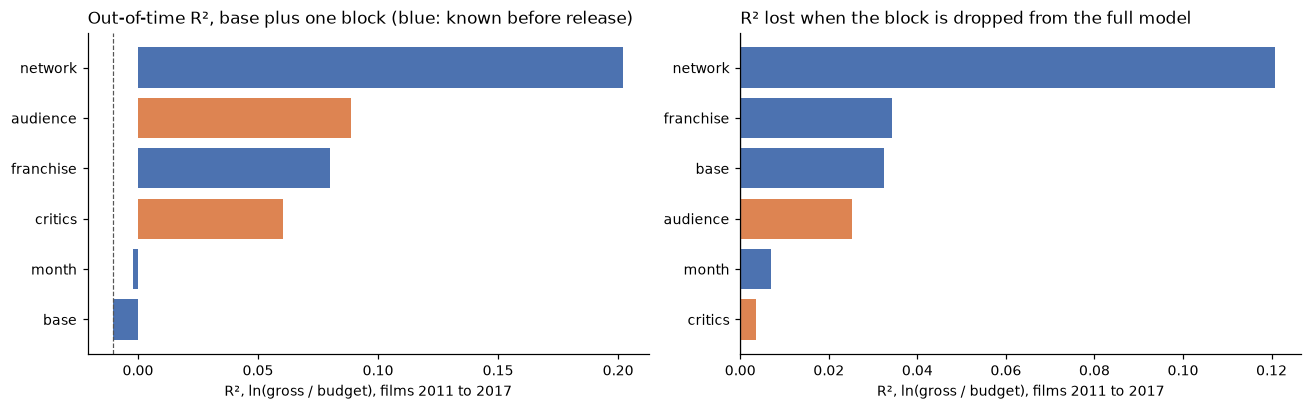

In [3]:
r = R[(R.model == "ridge") & R.block.isin(ALL)].set_index("block")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
order = r["R2 base + block"].sort_values().index
colors = ["#4c72b0" if b in PRE else "#dd8452" for b in order]
axes[0].barh(order, r.loc[order, "R2 base + block"], color=colors)
axes[0].axvline(r.loc["base", "R2 base + block"], color="#555", lw=0.8, ls="--")
axes[0].set_title("Out-of-time R², base plus one block (blue: known before release)", loc="left")
order2 = r["R2 lost when dropped"].sort_values().index
axes[1].barh(order2, r.loc[order2, "R2 lost when dropped"], color=["#4c72b0" if b in PRE else "#dd8452" for b in order2])
axes[1].axvline(0, color="#555", lw=0.8)
axes[1].set_title("R² lost when the block is dropped from the full model", loc="left")
for ax in axes:
    ax.set_xlabel("R², ln(gross / budget), films 2011 to 2017")
plt.tight_layout(); plt.show()

"Added to base" says how much a block knows on its own, and "lost when dropped" says how much it knows that no
other block does. A block can do well on its own and lose little when dropped if another block carries the same
information (critics and audience scores overlap, for instance). In the ridge rows, the network block leads on both:
0.202 added to base, and 0.121 lost when dropped (95% interval +0.097 to +0.149).

### Screenplays, on the films that have one

Do script features add anything on top of the network? Only a quarter of these films have a MovieSum screenplay, so
script features get their own test on that subset: base plus network, with and without the script block.

In [4]:
SCRIPT = ["characters", "density", "lead_share", "centralisation", "clustering", "modularity", "line_gini", "scenes",
          "words", "speeches_per_scene", "words_per_speech", "dialogue_share", "sent_mean", "sent_swing", "sent_ending"]
ds = d.join(sp[SCRIPT], how="inner")
BLOCKS_S = {"base": pd.concat([ds[["log_budget", "year"]], genres.loc[ds.index]], axis=1), "network": ds[NET], "script": ds[SCRIPT]}
tr_s, te_s = (ds.year <= 2010).values, (ds.year > 2010).values
def r2_s(blocks):
    X = pd.concat([BLOCKS_S[b] for b in blocks], axis=1).astype(float)
    for c in list(X.columns):
        if X[c].isna().any():
            X[c + "__missing"] = X[c].isna().astype(float); X[c] = X[c].fillna(X.loc[tr_s, c].mean())
    X = X.values
    m = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 25))).fit(X[tr_s], ds.log_mult.values[tr_s])
    return r2_score(ds.log_mult.values[te_s], m.predict(X[te_s]))
S = pd.Series({"base": r2_s(["base"]), "base + script": r2_s(["base", "script"]), "base + network": r2_s(["base", "network"]),
               "base + network + script": r2_s(["base", "network", "script"])})
print(f"{len(ds):,} films with a screenplay ({tr_s.sum():,} train, {te_s.sum():,} test)")
S.round(3)

1,333 films with a screenplay (957 train, 376 test)


base                      -0.152
base + script             -0.104
base + network             0.037
base + network + script    0.036
dtype: float64

## 2. Why does a studio's track record predict profit?

What is a studio's track record actually picking up? We run three tests, each against the studio track record's
rank correlation with a film's ln(multiple), net of budget and year:

- Producer or distributor? Distributors run marketing and release, while producing studios choose and make the film.
  If the distributor's record carries the signal, it's more about selling than choosing.
- A cheap-genre habit? We hold fixed the studio's typical budget and horror share in its earlier films.
- Skill or luck? For each director, we shuffle the order of their films many times and recompute "share of next
  films that are hits after a hit". If the real persistence sits inside the shuffled range, it's regression to the
  mean rather than a lasting knack.

In [5]:
def rank_partial(yv, x, z):
    r_ = stats.rankdata
    Z = np.column_stack([np.ones(len(yv))] + [r_(c) for c in np.atleast_2d(z.T)])
    res = lambda v: r_(v) - Z @ np.linalg.lstsq(Z, r_(v), rcond=None)[0]
    return stats.pearsonr(res(x), res(yv))

rows = []
both = d.dropna(subset=["studio_track", "distributor_track"])
for label, x, ctrl, sub in [
        ("studio track, net of budget and year", "studio_track", ["log_budget", "year"], d.dropna(subset=["studio_track"])),
        ("distributor track, net of budget and year", "distributor_track", ["log_budget", "year"], d.dropna(subset=["distributor_track"])),
        ("studio track, net of distributor track too", "studio_track", ["log_budget", "year", "distributor_track"], both),
        ("distributor track, net of studio track too", "distributor_track", ["log_budget", "year", "studio_track"], both),
        ("studio track, net of studio's prior budget and horror share", "studio_track",
         ["log_budget", "year", "studio_prior_budget", "studio_prior_horror"], d.dropna(subset=["studio_track", "studio_prior_budget"])),
        ("studio track, net of genre and franchise as well", "studio_track",
         ["log_budget", "year", "franchise"] + list(genres.columns), d.dropna(subset=["studio_track"]))]:
    zz = sub[ctrl].values if not set(genres.columns) & set(ctrl) else sub[["log_budget", "year", "franchise"]].join(genres).values
    rho, p = rank_partial(sub.log_mult.values, sub[x].values, zz)
    rows.append({"test": label, "films": len(sub), "rho": rho, "p": p})
pd.DataFrame(rows).round(4)

,test,films,rho,p
0,"studio track, net of budget and year",3793,0.2677,0.0
1,"distributor track, net of budget and year",4916,0.1686,0.0
2,"studio track, net of distributor track too",3589,0.2317,0.0
3,"distributor track, net of studio track too",3589,0.0971,0.0
4,"studio track, net of studio's prior budget and...",3793,0.2650,0.0
5,"studio track, net of genre and franchise as well",3793,0.2045,0.0


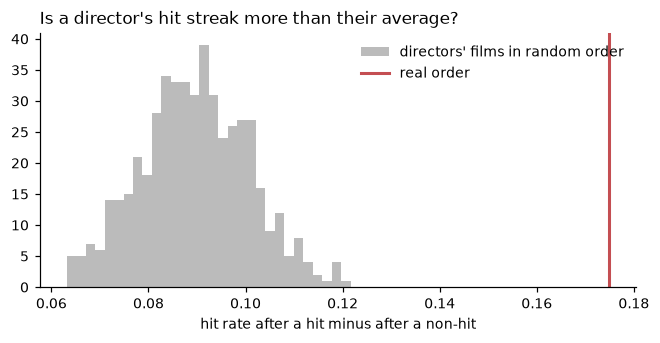

1,359 directors with 2+ clean films: hit after a hit 39%, after a non-hit 21%; gap +0.175 vs +0.090 with order shuffled (largest +0.122)


In [6]:
dir_edges = pd.read_csv(F / "graph/edges.csv", dtype={"source": str, "target": str}, usecols=["source", "target", "role"])
dir_edges = dir_edges[(dir_edges.role == "director") & dir_edges.target.isin(mv.index)]
cut = d.log_mult[train].quantile(0.75)
films_by_dir = {k: sorted(g.target, key=lambda t: (mv.year[t], t)) for k, g in dir_edges.groupby("source")}
films_by_dir = {k: v for k, v in films_by_dir.items() if len(v) >= 2}
is_hit = (mv.log_mult >= cut).to_dict()
def persistence(seqs):
    after_hit, after_non = [], []
    for s in seqs:
        h = [is_hit[t] for t in s]
        for a, b in zip(h, h[1:]):
            (after_hit if a else after_non).append(b)
    return np.mean(after_hit) - np.mean(after_non), np.mean(after_hit), np.mean(after_non)
obs_gap, obs_h, obs_n = persistence(films_by_dir.values())
rng = np.random.default_rng(SEED)
null_gap = [persistence([list(rng.permutation(s)) for s in films_by_dir.values()])[0] for _ in range(500)]
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(null_gap, bins=30, color="#bbbbbb", label="directors' films in random order")
ax.axvline(obs_gap, color="#c44e52", lw=2, label="real order")
ax.set_xlabel("hit rate after a hit minus after a non-hit"); ax.legend(frameon=False)
ax.set_title("Is a director's hit streak more than their average?", loc="left"); plt.show()
print(f"{len(films_by_dir):,} directors with 2+ clean films: hit after a hit {obs_h:.0%}, after a non-hit {obs_n:.0%}; "
      f"gap {obs_gap:+.3f} vs {np.mean(null_gap):+.3f} with order shuffled (largest {max(null_gap):+.3f})")

The real gap of +0.175 sits above every shuffled value (the largest is +0.122, the average +0.090). Shuffling keeps
each director's films and changes only their order. A director who makes hits on average still shows a gap after
shuffling, so the shuffled gap measures "some directors are better on average". The excess over it measures
momentum, whether a hit makes the next one likelier beyond that average. Part of that excess may be era rather than
momentum, since a director's consecutive films come from the same few years and the share of hits changes from era
to era.

## 3. Centrality instead of counts

Does it matter how well connected the people and companies are, beyond how many films they've made? Experience counts
films. Centrality asks how embedded someone is among other well-connected people. Both come from earlier films only
(the rolling networks in `film_features.py`). Here centrality is PageRank, which scores a node higher when it's
linked to nodes that are themselves well linked. Does PageRank add anything once budget, year and plain experience
are known?

In [7]:
rows = []
exp_cols = [c for c in d.columns if c.endswith("_experience")]
for c in ["people_pagerank_mean", "people_pagerank_max", "people_degree_mean", "company_pagerank_mean"]:
    sub = d.dropna(subset=[c] + exp_cols)
    rho, p = rank_partial(sub.log_mult.values, sub[c].values, sub[["log_budget", "year"]].values)
    rho2, p2 = rank_partial(sub.log_mult.values, sub[c].values, sub[["log_budget", "year"] + exp_cols].values)
    rows.append({"measure": c, "films": len(sub), "rho net of budget, year": rho, "p": p,
                 "rho net of experience too": rho2, "p ": p2})
cent = pd.DataFrame(rows)
cent.round(4)

,measure,films,"rho net of budget, year",p,rho net of experience too,p
0,people_pagerank_mean,4808,-0.0482,0.0008,-0.0026,0.8580
1,people_pagerank_max,4808,-0.0616,0.0000,-0.0289,0.0452
2,people_degree_mean,4808,-0.0470,0.0011,-0.0068,0.6366
3,company_pagerank_mean,4808,0.1641,0.0000,0.0008,0.9563


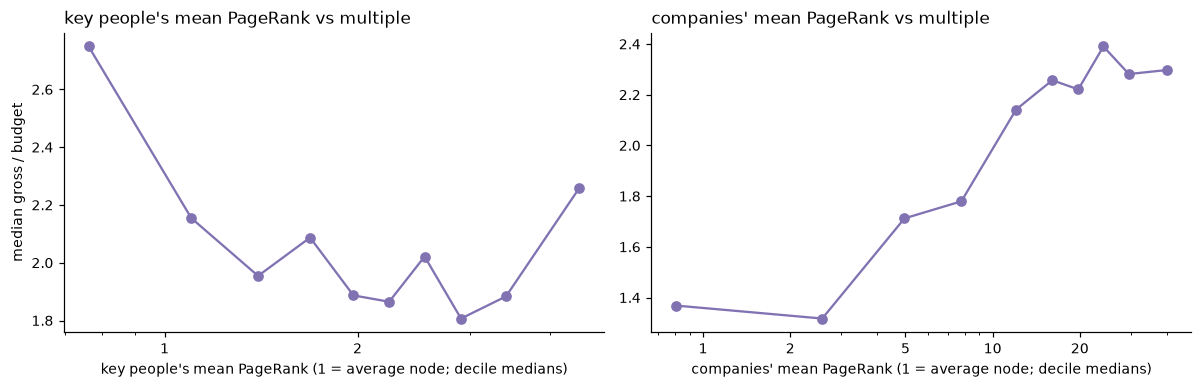

In [8]:
import matplotlib.ticker as mticker
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, c, label in ((axes[0], "people_pagerank_mean", "key people's mean PageRank"),
                     (axes[1], "company_pagerank_mean", "companies' mean PageRank")):
    sub = d.dropna(subset=[c])
    bins = pd.qcut(sub[c].rank(method="first"), 10, labels=False)
    g = sub.groupby(bins)
    ax.plot(g[c].median(), np.exp(g.log_mult.median()), "o-", color="#8172b2")
    ax.set_xscale("log"); ax.set_xlabel(f"{label} (1 = average node; decile medians)")
    ax.xaxis.set_major_locator(mticker.LogLocator(subs=[1, 2, 5])); ax.xaxis.set_minor_formatter(mticker.NullFormatter())
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}"))
    ax.set_title(label + " vs multiple", loc="left")
axes[0].set_ylabel("median gross / budget")
plt.tight_layout(); plt.show()

## 4. Company alliances

Do groups of companies that keep working together differ in how much their films return? Companies are linked when
they worked on the same clean film (1980 to 2017) as studio or distributor. Louvain community detection splits a
network into groups that are linked more densely inside than to each other. We run it in igraph with ten seeds. No
partition repeats exactly, so we keep the most frequent one and break ties by modularity (the output below shows how
closely the runs agree). Each community is a set of companies that keep working together. Each film
joins the community of most of its companies. Then we ask whether communities differ in profit after budget, year and
genre are removed, more than they would if the same films' residuals were shuffled within release year. This part
is descriptive, since it uses every year at once.

In [9]:
edges = pd.read_csv(F / "graph/edges.csv", dtype={"source": str, "target": str}, usecols=["source", "target", "role"])
ce = edges[edges.role.isin(["studio", "distributor"]) & edges.target.isin(d.index)]
film_cos = ce.groupby("target").source.apply(lambda s: sorted(set(s))).to_dict()
w = Counter()
for cos in film_cos.values():
    for a, b in combinations(cos, 2):
        w[(a, b)] += 1
names = sorted({n for p in w for n in p}); idx = {n: i for i, n in enumerate(names)}
pairs = sorted(w)
CG = ig.Graph(n=len(names), edges=[(idx[a], idx[b]) for a, b in pairs]); cw = [w[p] for p in pairs]
seen = Counter(); mods = {}; runs = []
for k in range(10):
    ig.set_random_number_generator(random.Random(SEED + k))
    part = CG.community_multilevel(weights=cw)
    runs.append(part.membership)
    key = tuple(sorted(tuple(sorted(c)) for c in part)); seen[key] += 1; mods[key] = CG.modularity(part, weights=cw)
best = max(seen, key=lambda k: (seen[k], mods[k]))
comm = {names[i]: ci for ci, c in enumerate(best) for i in c}
nmi = [ig.compare_communities(a, b, method="nmi") for a, b in combinations(runs, 2)]
print(f"company network: {len(names):,} companies, {len(pairs):,} links; {len(best)} communities, modularity "
      f"{mods[best]:.3f}; no partition repeats exactly (most frequent: {seen[best]} of 10 runs), but runs agree "
      f"closely: NMI between runs {np.mean(nmi):.3f} (min {min(nmi):.3f})")

X = np.column_stack([np.ones(len(d)), d.log_budget, d.year, genres.values])
resid = pd.Series(d.log_mult.values - X @ np.linalg.lstsq(X, d.log_mult.values, rcond=None)[0], index=d.index)
fc = {t: Counter(comm[c] for c in cos if c in comm).most_common(1)[0][0] for t, cos in film_cos.items()
      if any(c in comm for c in cos)}
fcs = pd.Series(fc)
big = fcs.value_counts(); big = big[big >= 40].index
sub = resid.loc[fcs.index[fcs.isin(big)]]; lab = fcs.loc[sub.index]
def eta2(v, l):
    m = v.mean(); return sum(len(g) * (g.mean() - m) ** 2 for _, g in v.groupby(l)) / ((v - m) ** 2).sum()
obs = eta2(sub, lab)
yrs = d.year.loc[sub.index].values; rng = np.random.default_rng(SEED); null = []
for _ in range(500):
    r = sub.values.copy()
    for yv in np.unique(yrs):
        i = np.where(yrs == yv)[0]; r[i] = r[rng.permutation(i)]
    null.append(eta2(pd.Series(r, index=sub.index), lab))
print(f"{len(big)} communities with 40+ films ({len(sub):,} films): share of residual profit variance between communities "
      f"{obs:.3f} vs {np.mean(null):.3f} +- {np.std(null):.3f} with residuals shuffled within year (largest {max(null):.3f})")
# the same test on every run's partition, so the result doesn't hang on one Louvain run
per_run = []
for mem in runs:
    cm_ = {names[i]: m for i, m in enumerate(mem)}
    f_ = pd.Series({t: Counter(cm_[c] for c in cos if c in cm_).most_common(1)[0][0] for t, cos in film_cos.items()
                    if any(c in cm_ for c in cos)})
    keep = f_.value_counts(); keep = keep[keep >= 40].index
    s_ = resid.loc[f_.index[f_.isin(keep)]]
    per_run.append(eta2(s_, f_.loc[s_.index]))
print(f"across all 10 runs: between-community share {min(per_run):.3f} to {max(per_run):.3f}, every run above the "
      f"largest shuffled value ({max(null):.3f}): {all(v > max(null) for v in per_run)}")

deg = Counter(c for cos in film_cos.values() for c in cos)
summary = []
for ci in big:
    members = [n for n, c in comm.items() if c == ci]
    top3 = sorted(members, key=lambda n: -deg[n])[:3]
    films = fcs.index[fcs == ci]
    summary.append({"community": ci, "films": len(films), "biggest companies": ", ".join(nodes.label[n] for n in top3),
                    "median multiple": math.exp(d.log_mult.loc[films].median()),
                    "mean residual": resid.loc[films].mean()})
alliances = pd.DataFrame(summary).sort_values("mean residual", ascending=False)
alliances.round(2).head(12)

company network: 2,972 companies, 16,253 links; 60 communities, modularity 0.490; no partition repeats exactly (most frequent: 1 of 10 runs), but runs agree closely: NMI between runs 0.724 (min 0.672)


12 communities with 40+ films (5,258 films): share of residual profit variance between communities 0.032 vs 0.002 +- 0.001 with residuals shuffled within year (largest 0.006)
across all 10 runs: between-community share 0.031 to 0.038, every run above the largest shuffled value (0.006): True


,community,films,biggest companies,median multiple,mean residual
5,9,493,"Paramount Pictures, DreamWorks Pictures, Ambli...",2.54,0.32
3,2,592,"Universal Pictures, Relativity Media, StudioCanal",2.30,0.25
4,11,503,"20th Century Studios, Regency Enterprises, Fox...",2.42,0.23
6,8,427,"Walt Disney Studios Motion Pictures, Walt Disn...",2.47,0.16
1,0,733,"Warner Bros. Pictures, New Line Cinema, Villag...",2.01,0.06
0,7,739,"Columbia Pictures, Sony Pictures Releasing, Tr...",2.06,0.02
9,6,206,"Miramax, Dimension Films, Buena Vista Internat...",2.03,-0.01
11,4,80,"PolyGram Filmed Entertainment, Gramercy Pictur...",1.85,-0.03
10,10,191,"Metro-Goldwyn-Mayer, United Artists, Metro-Gol...",1.94,-0.13
8,3,265,"EuropaCorp, Groupe Canal+, Gaumont",1.53,-0.15


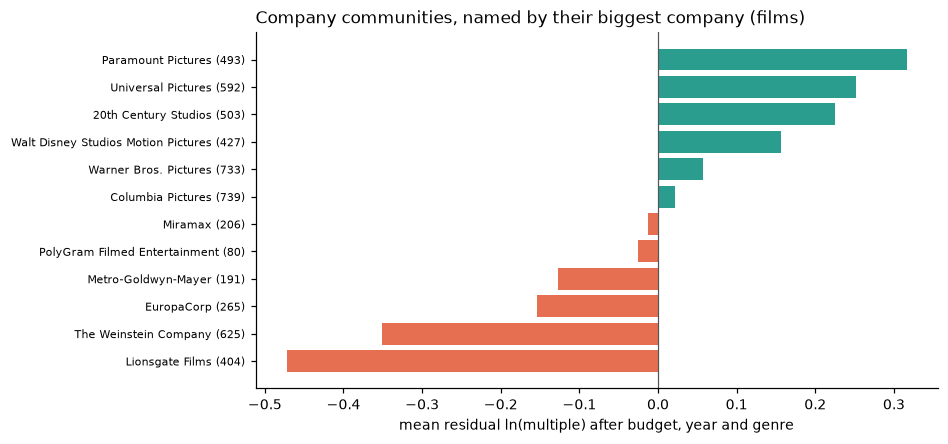

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.2))
a = alliances.sort_values("mean residual")
lbl = [s.split(",")[0] + f" ({n})" for s, n in zip(a["biggest companies"], a.films)]
ax.barh(lbl, a["mean residual"], color=["#2a9d8f" if v > 0 else "#e76f51" for v in a["mean residual"]])
ax.axvline(0, color="#555", lw=0.8)
ax.set_xlabel("mean residual ln(multiple) after budget, year and genre")
ax.set_title("Company communities, named by their biggest company (films)", loc="left")
ax.tick_params(axis="y", labelsize=7); plt.show()

## 5. Profit against being liked

Do the films critics love also make money? We split films by Rotten Tomatoes (loved: 80 or more, panned: 40 or
less) and by return (hit: top quarter, flop: grossed less than budget). The interesting cells are the disagreements,
loved flops and panned hits. Who makes them? We compare each with the agreeing films of the same critical standing
(loved flops with loved hits, panned hits with panned flops), on measures known before release. Each comparison uses
a Mann-Whitney test, which asks whether one group's values tend to run higher than the other's, and the q column
adjusts those p-values for testing nine measures at once.

In [11]:
q = d.dropna(subset=["rt"]).copy()
q["liked"] = np.where(q.rt >= 80, "loved", np.where(q.rt <= 40, "panned", "mixed"))
q["money"] = np.where(q.log_mult >= cut, "hit", np.where(q.multiple < 1, "flop", "middle"))
tab = pd.crosstab(q.liked, q.money).loc[["loved", "mixed", "panned"], ["flop", "middle", "hit"]]
print(f"Spearman, Rotten Tomatoes vs ln(multiple): {stats.spearmanr(q.rt, q.log_mult)[0]:+.3f} ({len(q):,} films)")
tab

Spearman, Rotten Tomatoes vs ln(multiple): +0.253 (3,933 films)


money,flop,middle,hit
liked,,,
loved,158,395,418
mixed,452,814,402
panned,441,648,205


In [12]:
COMPARE = {"log_budget": "ln(budget)", "franchise": "franchise", "director_experience": "director's earlier films",
           "director_track": "director's track record", "studio_track": "studio's track record",
           "studio_experience": "studio's earlier films", "cast_experience": "cast's earlier films",
           "people_pagerank_mean": "key people's PageRank", "company_pagerank_mean": "companies' PageRank"}
def compare(a, b, la, lb):
    rows = []
    for c, label in COMPARE.items():
        x, z = a[c].dropna(), b[c].dropna()
        p = stats.mannwhitneyu(x, z).pvalue if len(x) > 5 and len(z) > 5 else np.nan
        stat = (lambda v: v.mean()) if c == "franchise" else (lambda v: v.median())
        rows.append({"measure": label + (" (share)" if c == "franchise" else " (median)"), la: stat(x), lb: stat(z), "p": p})
    t = pd.DataFrame(rows)
    ok = t.p.notna()
    o = np.argsort(t.p[ok].values); pv = t.p[ok].values[o] * ok.sum() / np.arange(1, ok.sum() + 1)
    pv = np.minimum.accumulate(pv[::-1])[::-1]; qv = np.empty_like(pv); qv[o] = np.minimum(pv, 1)
    t.loc[ok, "q"] = qv
    return t
lf, lh = q[(q.liked == "loved") & (q.money == "flop")], q[(q.liked == "loved") & (q.money == "hit")]
ph, pf = q[(q.liked == "panned") & (q.money == "hit")], q[(q.liked == "panned") & (q.money == "flop")]
print(f"loved flops {len(lf)} vs loved hits {len(lh)}")
compare(lf, lh, "loved flops", "loved hits").round(3)

loved flops 158 vs loved hits 418


,measure,loved flops,loved hits,p,q
0,ln(budget) (median),16.118,16.213,0.629,0.716
1,franchise (share),0.063,0.301,0.000,0.000
2,director's earlier films (median),4.000,3.750,0.764,0.764
3,director's track record (median),0.838,1.052,0.010,0.021
4,studio's track record (median),0.642,0.824,0.004,0.011
5,studio's earlier films (median),6.000,8.000,0.024,0.043
6,cast's earlier films (median),5.000,5.500,0.636,0.716
7,key people's PageRank (median),1.857,1.871,0.426,0.639
8,companies' PageRank (median),5.005,10.246,0.000,0.000


In [13]:
print(f"panned hits {len(ph)} vs panned flops {len(pf)}")
compare(ph, pf, "panned hits", "panned flops").round(3)

panned hits 205 vs panned flops 441


,measure,panned hits,panned flops,p,q
0,ln(budget) (median),16.524,17.034,0.000,0.000
1,franchise (share),0.541,0.107,0.000,0.000
2,director's earlier films (median),2.000,4.000,0.000,0.000
3,director's track record (median),1.169,0.844,0.000,0.000
4,studio's track record (median),0.835,0.624,0.000,0.000
5,studio's earlier films (median),10.333,10.750,0.498,0.498
6,cast's earlier films (median),4.667,9.000,0.000,0.000
7,key people's PageRank (median),1.799,2.274,0.000,0.000
8,companies' PageRank (median),17.059,12.479,0.002,0.002


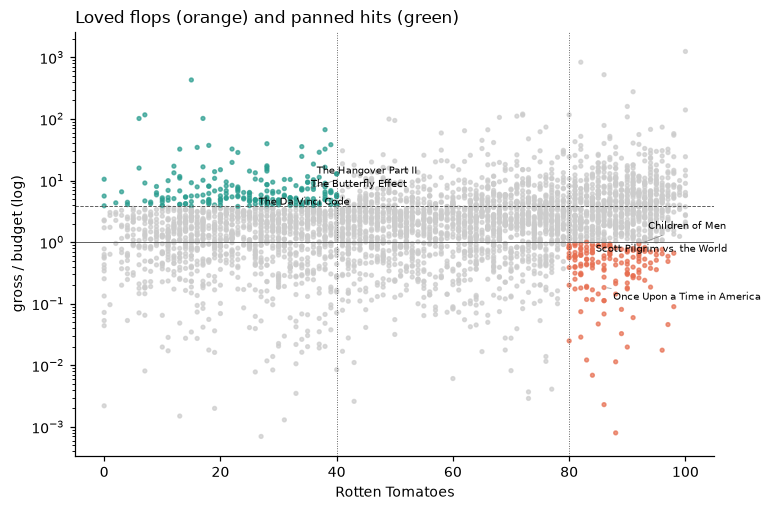

In [14]:
fig, ax = plt.subplots(figsize=(7.5, 5))
colors = np.where((q.liked == "loved") & (q.money == "flop"), "#e76f51",
          np.where((q.liked == "panned") & (q.money == "hit"), "#2a9d8f", "#cccccc"))
ax.scatter(q.rt, q.multiple, c=colors, s=6, alpha=0.7)
ax.set_yscale("log"); ax.axhline(1, color="#555", lw=0.6); ax.axhline(math.exp(cut), color="#555", lw=0.6, ls="--")
ax.axvline(80, color="#555", lw=0.6, ls=":"); ax.axvline(40, color="#555", lw=0.6, ls=":")
ax.set_xlabel("Rotten Tomatoes"); ax.set_ylabel("gross / budget (log)")
ax.set_title("Loved flops (orange) and panned hits (green)", loc="left")
for k, (_, r) in enumerate(pd.concat([lf.nlargest(3, "votes"), ph.nlargest(3, "votes")]).iterrows()):
    ax.annotate(r.label, (r.rt, r.multiple), xytext=(6, 10 - 9 * (k % 3)), textcoords="offset points", fontsize=6.5,
                arrowprops={"arrowstyle": "-", "lw": 0.4, "color": "#777"})
plt.show()

## Summary

Each line answers one section. It's printed from the cells above, so it changes with the data.

In [15]:
rr = R[R.model == "ridge"].set_index("block")
rb = R[R.model == "boosting"].set_index("block")
best_pre = rr.loc[[b for b in PRE if b != "base"], "R2 base + block"].idxmax()
print(f"1. Out of time (2011-2017), ridge R2: base {rr.loc['base', 'R2 base + block']:.3f}; base + network "
      f"{rr.loc['network', 'R2 base + block']:.3f}; all pre-release {rr.loc['all before release', 'R2 base + block']:.3f}; "
      f"everything incl. reviews {rr.loc['everything', 'R2 base + block']:.3f}. Best pre-release block: {best_pre}. "
      f"Boosting: all pre-release {rb.loc['all before release', 'R2 base + block']:.3f}.")
print(f"   Screenplay subset: base {S['base']:.3f}, + script {S['base + script']:.3f}, + network {S['base + network']:.3f}, "
      f"+ both {S['base + network + script']:.3f}.")
t2 = pd.DataFrame(rows)
print(f"2. Director hit streaks: gap {obs_gap:+.3f} real vs {np.mean(null_gap):+.3f} shuffled.")
print(f"3. Key people's PageRank net of experience: rho {cent.set_index('measure').loc['people_pagerank_mean', 'rho net of experience too']:+.3f}; "
      f"companies' PageRank: {cent.set_index('measure').loc['company_pagerank_mean', 'rho net of experience too']:+.3f}.")
print(f"4. Company communities: {min(per_run):.3f} to {max(per_run):.3f} of residual variance between communities "
      f"across 10 Louvain runs, vs {np.mean(null):.3f} by chance.")
print(f"5. Rotten Tomatoes vs multiple rho {stats.spearmanr(q.rt, q.log_mult)[0]:+.3f}; {len(lf)} loved flops, {len(ph)} panned hits.")

1. Out of time (2011-2017), ridge R2: base -0.010; base + network 0.202; all pre-release 0.244; everything incl. reviews 0.312. Best pre-release block: network. Boosting: all pre-release 0.257.
   Screenplay subset: base -0.152, + script -0.104, + network 0.037, + both 0.036.
2. Director hit streaks: gap +0.175 real vs +0.090 shuffled.
3. Key people's PageRank net of experience: rho -0.003; companies' PageRank: +0.001.
4. Company communities: 0.031 to 0.038 of residual variance between communities across 10 Louvain runs, vs 0.002 by chance.
5. Rotten Tomatoes vs multiple rho +0.253; 158 loved flops, 205 panned hits.
